# XAI aplicado a scoring de crédito: ¿quién va a dejar de pagar y por qué?

**Asignatura:** Explainable AI – Proyecto final,MUIA ICAI Comillas 2026/27
**Autor:** Guzmán Ignacio Pérez Ibarz

En este notebook entreno un modelo que predice si un cliente de tarjeta de crédito va a dejar de pagar el mes que viene,
y luego lo estudio con varias técnicas de explicabilidad para ver qué criterios pesan más, si me puedo fiar de esas
explicaciones y qué se puede hacer con ellas.

**Dónde está cada cosa del enunciado**

| Enunciado | Dónde |
|---|---|
| 1. Problema y dataset | 1 y 2 |
| 2. Modelos y evaluación (sin overfitting) | 3 |
| 3. Técnicas XAI (global + local + evaluación) | 4 (global y local) y 5 (sanity checks) |
| 4. Uso accionable (4.1 mejora, 4.2 negocio, 4.3 equidad) | 6, 7 y 8 |
| 5. Crítica de las explicaciones | 5 y 9 |

## 1. El problema

**Tarea.** Clasificación binaria: dadas las características de un cliente y su historial de los últimos 6 meses, predecir
si no pagará el mes siguiente (`default = 1`). Es el caso típico de riesgo de crédito.

**Quién usa esto y por qué le importa explicarlo**
- **Analista de riesgos / gestor:** necesita saber por qué el modelo marca a alguien, no solo que lo marque, para fiarse o corregirlo.
- **El cliente:** si le niegan algo o le suben el riesgo, tiene derecho a una explicación y a saber qué podría cambiar.
- **El regulador:** el scoring de crédito se considera de alto riesgo en el AI Act (Anexo III) y el RGPD (art. 22) protege frente a
  decisiones automatizadas.

**Datos.** *Default of Credit Card Clients*, UCI Machine Learning Repository (id 350), un banco de Taiwán, abril–septiembre de 2005.
30.000 clientes, 23 variables (límite de crédito, sexo, educación, estado civil, edad, 6 meses de estado de pago, 6 de facturas y 6 de pagos)
y el objetivo `default payment next month`. Link: https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients  ·
Paper del dataset: Yeh & Lien (2009), *Expert Systems with Applications* 36(2).

Me gustaria mencionar que los datos son del 2005, por lo que puede haber cambiado todo hoy en dia. 

In [1]:
# --- Imports y configuración general ---
# Si te falta algo:  pip install -r requirements.txt   (mejor dentro de un venv)
import os, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import xgboost as xgb
from scipy.stats import spearmanr
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, f1_score,
                             precision_score, recall_score, roc_curve)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")
SEMILLA = 42                      
np.random.seed(SEMILLA)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
#RAPIDO = os.environ.get("RAPIDO") == "1"

# Carpeta raíz del proyecto (sirve si lo lanzas desde notebooks/ o desde la raíz)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
(RAIZ / "data").mkdir(exist_ok=True)
(RAIZ / "reports" / "figures").mkdir(parents=True, exist_ok=True)

def guarda(nombre):
    """Guarda la figura actual en reports/figures para pegarla luego en el informe."""
    plt.tight_layout()
    plt.savefig(RAIZ / "reports" / "figures" / f"{nombre}.png", dpi=170, bbox_inches="tight")

RES = {} #para el informe!!

## 2. Datos: carga, limpieza y partición

Primero intento bajarlo con `ucimlrepo`. Si no hay internet, descarga el CSV a mano desde la página de UCI (o Kaggle) y
guárdalo como `data/taiwan_default.csv`; el código acepta ambos formatos.

In [2]:
# --- Carga ---
NOMBRES = (["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]
           + ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]                  
           + [f"BILL_AMT{i}" for i in range(1, 7)]                                    
           + [f"PAY_AMT{i}" for i in range(1, 7)])                                    
PAY = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAYAMT = [f"PAY_AMT{i}" for i in range(1, 7)]

csv = RAIZ / "data" / "taiwan_default.csv"
if csv.exists():
    df = pd.read_csv(csv)
    df = df.drop(columns=[c for c in ["ID"] if c in df.columns])
    df = df.rename(columns={"default.payment.next.month": "default", "default payment next month": "default",
                            "PAY_1": "PAY_0", "Y": "default"})
    if "X1" in df.columns:                      
        df = df.rename(columns=dict(zip([f"X{i}" for i in range(1, 24)], NOMBRES)))
else:
    from ucimlrepo import fetch_ucirepo
    d = fetch_ucirepo(id=350)
    X_raw = d.data.features.copy()
    X_raw.columns = NOMBRES                     
    df = X_raw.assign(default=d.data.targets.iloc[:, 0].values)
    df.to_csv(csv, index=False)                 

print("Filas x columnas:", df.shape)
df.head(3)

Filas x columnas: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


In [3]:
# Limpieza
# EDUCATION y MARRIAGE traen códigos que no vienen en la descripción oficial (0, 5, 6...): los meto en "otros".
print("EDUCATION antes:", df["EDUCATION"].value_counts().to_dict())
df["EDUCATION"] = df["EDUCATION"].where(df["EDUCATION"].isin([1, 2, 3]), 4)
df["MARRIAGE"] = df["MARRIAGE"].where(df["MARRIAGE"].isin([1, 2]), 3)

n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)      # hay unas pocas filas duplicadas
print(f"Duplicados eliminados: {n0 - len(df)}")
print(f"Tasa de impago: {df['default'].mean():.1%}  -> clases desbalanceadas, ojo con usar solo accuracy")
print("Nulos totales:", int(df.isna().sum().sum()))

EDUCATION antes: {2: 14030, 1: 10585, 3: 4917, 5: 280, 4: 123, 6: 51, 0: 14}
Duplicados eliminados: 35
Tasa de impago: 22.1%  -> clases desbalanceadas, ojo con usar solo accuracy
Nulos totales: 0


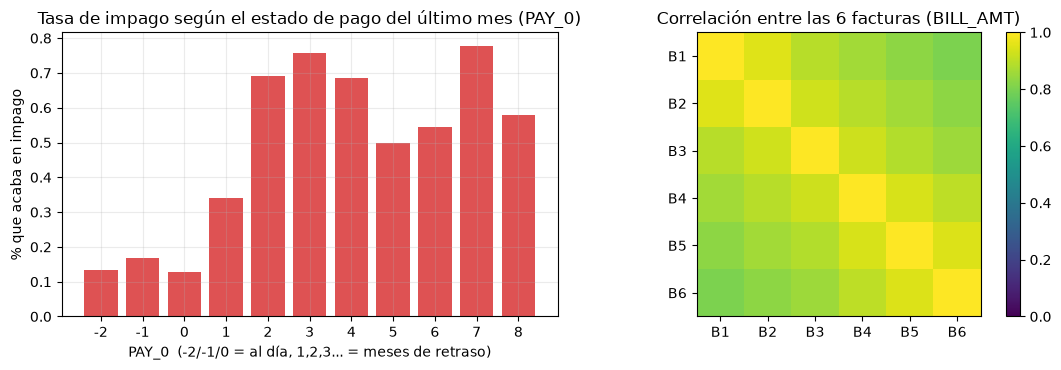

Correlación media entre facturas: 0.89  (muy redundantes -> pista para 6)


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

tasa = df.groupby("PAY_0")["default"].mean()
ax[0].bar(tasa.index.astype(str), tasa.values, color="tab:red", alpha=0.8)
ax[0].set_title("Tasa de impago según el estado de pago del último mes (PAY_0)")
ax[0].set_xlabel("PAY_0  (-2/-1/0 = al día, 1,2,3... = meses de retraso)")
ax[0].set_ylabel("% que acaba en impago")

corr = df[BILL].corr()
im = ax[1].imshow(corr, vmin=0, vmax=1, cmap="viridis")
ax[1].set_xticks(range(6)); ax[1].set_yticks(range(6))
ax[1].set_xticklabels([f"B{i}" for i in range(1, 7)]); ax[1].set_yticklabels([f"B{i}" for i in range(1, 7)])
ax[1].set_title("Correlación entre las 6 facturas (BILL_AMT)")
ax[1].grid(False); plt.colorbar(im, ax=ax[1])
guarda("01_eda"); plt.show()

RES["tasa_impago"] = float(df["default"].mean())
RES["corr_media_facturas"] = float(corr.values[np.triu_indices(6, 1)].mean())
print(f"Correlación media entre facturas: {RES['corr_media_facturas']:.2f}  (muy redundantes -> pista para 6)")

In [5]:
# Partición train / validación / test = 60 / 20 / 20, estratificada
# Es una foto de un único corte temporal (no hay serie), así que un split aleatorio estratificado vale.
y = df["default"]
X = df.drop(columns="default")

X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEMILLA)

# SEX es un atributo sensible: No lo uso como entrada del modelo, pero lo guardo aparte para auditar (8)
sexo_va = X_va["SEX"].map({1: "hombre", 2: "mujer"})     # en UCI: 1 = hombre, 2 = mujer
sexo_te = X_te["SEX"].map({1: "hombre", 2: "mujer"})
FEATS = [c for c in X.columns if c != "SEX"]
X_tr, X_va, X_te = X_tr[FEATS], X_va[FEATS], X_te[FEATS]

print(f"train {len(X_tr)} | val {len(X_va)} | test {len(X_te)}   (tasa de impago: "
      f"{y_tr.mean():.3f} / {y_va.mean():.3f} / {y_te.mean():.3f})")

train 17979 | val 5993 | test 5993   (tasa de impago: 0.221 / 0.221 / 0.221)


## 3. Modelos y evaluación

Pruebo tres cosas, de más simple a más potente:
1. **Dummy** (siempre predice la tasa base): el suelo. Si el modelo no lo mejora, no sirve.
2. **Regresión logística**: baseline interpretable, el que usaría un banco "clásico".
3. **XGBoost**: el modelo principal, del que sacaré las explicaciones. Uso *early stopping* sobre validación para que no
   se pase de árboles, y elijo entre unas pocas configuraciones por AUC de validación.

Métricas: **ROC-AUC** (ranking), **PR-AUC** (mejor con clases desbalanceadas), **Brier** (calidad de las probabilidades) y
**F1/precisión/recall** con un umbral elegido en validación (el que maximiza F1). Todo se decide con train+val; test solo al final.

In [6]:
#Funciones de métricas
def umbral_f1(y_real, p):
    """Umbral que maximiza F1 (se calcula SOLO con validación)."""
    grid = np.arange(0.05, 0.95, 0.01)
    return float(grid[np.argmax([f1_score(y_real, p >= t) for t in grid])])

def metricas(y_real, p, t):
    return {"ROC-AUC": roc_auc_score(y_real, p), "PR-AUC": average_precision_score(y_real, p),
            "Brier": brier_score_loss(y_real, p), "F1": f1_score(y_real, p >= t),
            "Precisión": precision_score(y_real, p >= t, zero_division=0),
            "Recall": recall_score(y_real, p >= t), "umbral": t}

# Baselines 
dummy = DummyClassifier(strategy="prior").fit(X_tr, y_tr)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_tr, y_tr)

In [7]:
# XGBoost: busco entre unas pocas configuraciones (poca profundidad = más difícil que se sobreajuste)
BASE = dict(subsample=0.8, colsample_bytree=0.8, min_child_weight=5, reg_lambda=5.0,
            eval_metric="auc", random_state=SEMILLA, n_jobs=-1)
candidatos = [dict(max_depth=2, learning_rate=0.05), dict(max_depth=3, learning_rate=0.05),
              dict(max_depth=4, learning_rate=0.05), dict(max_depth=6, learning_rate=0.05),
              dict(max_depth=3, learning_rate=0.02)]
N_ARB = 1500

def entrena_xgb(cfg, Xtr, ytr, Xva, yva):
    """XGBoost con early stopping sobre validación."""
    m = xgb.XGBClassifier(n_estimators=N_ARB, early_stopping_rounds=50, **BASE, **cfg)
    return m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)

resultados = []
for cfg in candidatos:
    m = entrena_xgb(cfg, X_tr, y_tr, X_va, y_va)
    resultados.append((roc_auc_score(y_va, m.predict_proba(X_va)[:, 1]), cfg, m))
    print(f"{cfg}  -> AUC val = {resultados[-1][0]:.4f}   (árboles: {m.best_iteration + 1})")

auc_val, CFG, modelo = max(resultados, key=lambda r: r[0])     # me quedo con la mejor en validación
N_OPT = modelo.best_iteration + 1
print(f"\nMe quedo con {CFG} y {N_OPT} árboles")

def xgb_fijo(cfg, n=None):
    """Mismo modelo sin early stopping (para reentrenar con datos remuestreados, CV, etc.)."""
    return xgb.XGBClassifier(n_estimators=n or N_OPT, **BASE, **cfg)

{'max_depth': 2, 'learning_rate': 0.05}  -> AUC val = 0.7845   (árboles: 462)
{'max_depth': 3, 'learning_rate': 0.05}  -> AUC val = 0.7854   (árboles: 265)
{'max_depth': 4, 'learning_rate': 0.05}  -> AUC val = 0.7866   (árboles: 139)
{'max_depth': 6, 'learning_rate': 0.05}  -> AUC val = 0.7863   (árboles: 79)
{'max_depth': 3, 'learning_rate': 0.02}  -> AUC val = 0.7849   (árboles: 597)

Me quedo con {'max_depth': 4, 'learning_rate': 0.05} y 139 árboles


In [8]:
# Comparación de modelos. El umbral sale de VALIDACIÓN y se aplica igual en test
modelos = {"Dummy": dummy, "Regresión logística": logreg, "XGBoost": modelo}
p_va_all = {k: m.predict_proba(X_va)[:, 1] for k, m in modelos.items()}
p_te_all = {k: m.predict_proba(X_te)[:, 1] for k, m in modelos.items()}
umbrales = {k: umbral_f1(y_va, p) for k, p in p_va_all.items()}

tabla_te = pd.DataFrame({k: metricas(y_te, p_te_all[k], umbrales[k]) for k in modelos}).T
print("=== TEST ===")
display(tabla_te.round(4))

p_va, p_te = p_va_all["XGBoost"], p_te_all["XGBoost"]
UMBRAL = umbrales["XGBoost"]
RES["metricas_test"] = tabla_te.round(4).to_dict()

=== TEST ===


,ROC-AUC,PR-AUC,Brier,F1,Precisión,Recall,umbral
Dummy,0.5000,0.2213,0.1723,0.3623,0.2213,1.0000,0.05
Regresión logística,0.7142,0.5044,0.1456,0.4929,0.5369,0.4555,0.29
XGBoost,0.7731,0.5548,0.1356,0.5345,0.5128,0.5581,0.27


AUC  train 0.8164 | val 0.7866 | test 0.7731   (gap train-test = +0.0433)
AUC en CV 5 folds (solo train): 0.7846 ± 0.0049
AUC test = 0.7731   IC95% bootstrap = [0.7581, 0.7874]


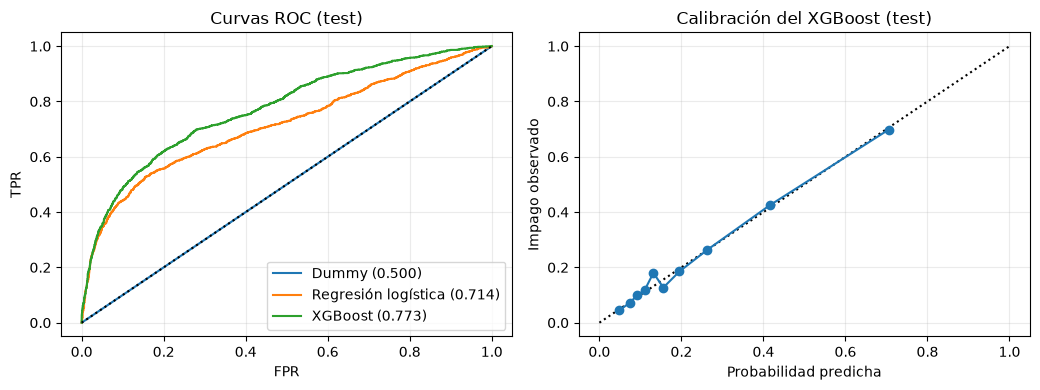

In [9]:
# Chequeo de sobreajuste del modelo: 
auc_tr = roc_auc_score(y_tr, modelo.predict_proba(X_tr)[:, 1])
auc_va = roc_auc_score(y_va, p_va)
auc_te = roc_auc_score(y_te, p_te)
print(f"AUC  train {auc_tr:.4f} | val {auc_va:.4f} | test {auc_te:.4f}   (gap train-test = {auc_tr - auc_te:+.4f})")

cv = cross_val_score(xgb_fijo(CFG), X_tr, y_tr, cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA),
                     scoring="roc_auc", n_jobs=1)
print(f"AUC en CV 5 folds (solo train): {cv.mean():.4f} ± {cv.std():.4f}")

# IC 95 % del AUC de test con bootstrap
rng = np.random.default_rng(SEMILLA)
B = 1000
boot = []
for _ in range(B):
    idx = rng.integers(0, len(y_te), len(y_te))
    boot.append(roc_auc_score(y_te.values[idx], p_te[idx]))
ic = np.percentile(boot, [2.5, 97.5])
print(f"AUC test = {auc_te:.4f}   IC95% bootstrap = [{ic[0]:.4f}, {ic[1]:.4f}]")

RES.update(auc_train=auc_tr, auc_val=auc_va, auc_test=auc_te, cv_auc=[cv.mean(), cv.std()], ic_auc_test=ic.tolist())

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4))
for k in modelos:
    fpr, tpr, _ = roc_curve(y_te, p_te_all[k]); ax[0].plot(fpr, tpr, label=f"{k} ({roc_auc_score(y_te, p_te_all[k]):.3f})")
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].set_title("Curvas ROC (test)"); ax[0].legend()
fr, mp = calibration_curve(y_te, p_te, n_bins=10, strategy="quantile")
ax[1].plot([0, 1], [0, 1], "k:"); ax[1].plot(mp, fr, "o-"); ax[1].set_title("Calibración del XGBoost (test)")
ax[1].set_xlabel("Probabilidad predicha"); ax[1].set_ylabel("Impago observado")
guarda("02_modelo"); plt.show()

**Como lo leo:** el AUC baja de 0,816 en train a 0,787 en validacion y 0,773 en test, con un CV de 0,785 ± 0,005, asi que hay algo de sobreajuste pero poco (gap de 0,04 entre train y test) y como los arboles son poco profundos y uso early stopping no me preocupa. El IC95% del test, [0,758, 0,787], contiene el valor de validacion asi que el numero es bastante estable y la calibracion tambien sale bien, con la curva casi pegada a la diagonal.

Lo que si me ha llamado la atencion es que XGBoost gana a la regresion logistica con bastante diferencia (0,773 de AUC frente a 0,714, y tambien mejora el PR-AUC y el Brier) cuando esperaba que estuvieran mas cerca. Mi hipotesis es que la logistica trata PAY_* como una variable lineal cuando el efecto claramente no lo es, pero eso no lo he comprobado. Aun asi la mejora justifica usar el modelo mas complejo.

Con el umbral de 0,27, que maximiza el F1 en validacion, el modelo detecta el 56 % de los impagos pero la mitad de las alertas son falsas alarmas, o sea que es util sin ser espectacular y por eso en 7 trato el umbral como una decision de negocio y no como algo puramente tecnico.

## 4. Explicabilidad: global y local

Uso técnicas distintas que se complementan:

| Técnica | Tipo | Por qué la uso |
|---|---|---|
| **SHAP (TreeSHAP)** | global y local | Es exacta y rápida para árboles; me da el peso de cada variable en cada cliente y en media. Va en log-odds. |
| **Permutation importance** | global | Mide cuánto empeora el AUC al romper una variable, es agnóstica y me sirve para contrastar SHAP. |
| **PDP / ICE** | global | Enseña la forma del efecto (no solo el tamaño). |
| **LIME** | local | Otra explicación local, sin relación con SHAP, para ver si coinciden. |
| **"Que pasaria si"** | local | Un contrafactual casero: cambio cosas de un cliente y miro si el modelo cambia de opinión. |

### 4.1 Global

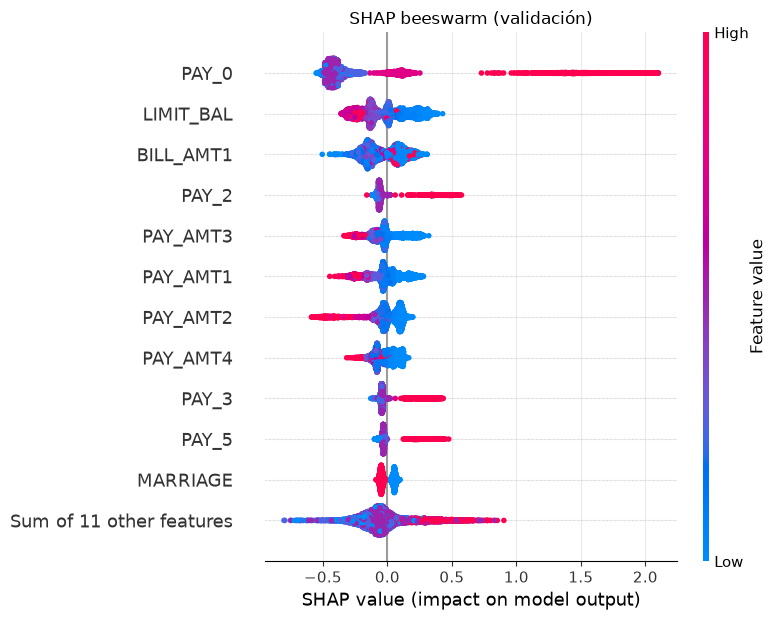

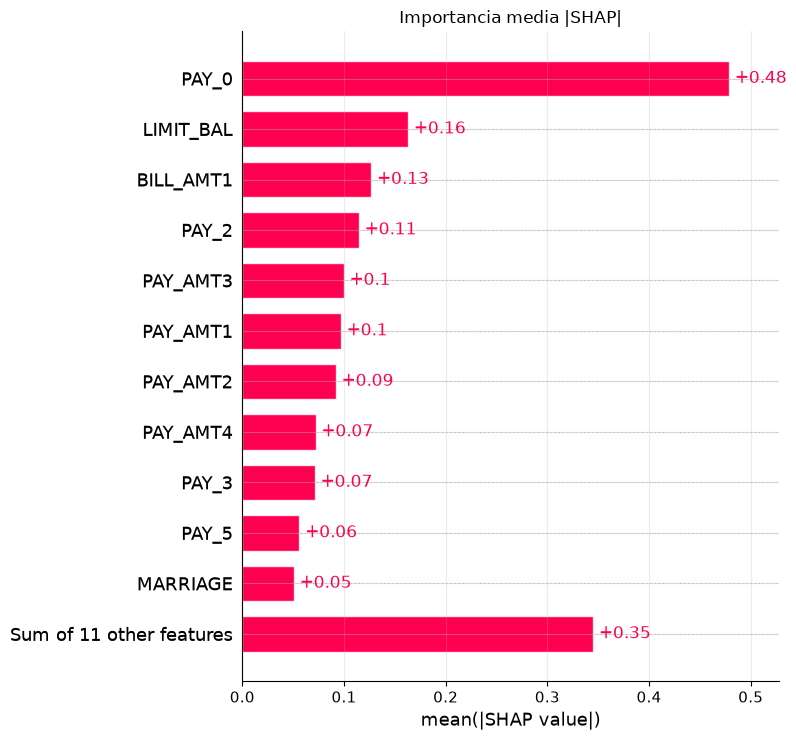

In [10]:
# SHAP global (sobre el set de validación)
explainer = shap.TreeExplainer(modelo)
sv = explainer(X_va)                      

plt.figure(); shap.plots.beeswarm(sv, max_display=12, show=False); plt.title("SHAP beeswarm (validación)")
guarda("03_shap_beeswarm"); plt.show()

plt.figure(); shap.plots.bar(sv, max_display=12, show=False); plt.title("Importancia media |SHAP|")
guarda("03_shap_bar"); plt.show()

In [11]:
# Contrasto con otras dos medidas de importancia: permutation importance y ganancia de XGBoost
imp_shap = pd.Series(np.abs(sv.values).mean(axis=0), index=FEATS)
pi = permutation_importance(modelo, X_va, y_va, scoring="roc_auc", n_repeats=8,
                            random_state=SEMILLA, n_jobs=-1)
imp_perm = pd.Series(pi.importances_mean, index=FEATS)
imp_gain = pd.Series(modelo.get_booster().get_score(importance_type="total_gain")).reindex(FEATS).fillna(0)

imp = pd.DataFrame({"mean|SHAP|": imp_shap, "permutation (caída AUC)": imp_perm, "ganancia XGB": imp_gain})
imp = imp.sort_values("mean|SHAP|", ascending=False)
display(imp.head(10).round(4))

# Correlación de Spearman para ver si se parecen los ranking
rho = imp.rank(ascending=False).corr(method="spearman")
display(rho.round(2))
ORDEN = imp_shap.sort_values(ascending=False).index.tolist() 
top5_shap = set(ORDEN[:5]); top5_perm = set(imp_perm.sort_values(ascending=False).index[:5])
print("Top-5 en común SHAP vs permutation:", sorted(top5_shap & top5_perm))
RES["top10_shap"] = imp_shap.sort_values(ascending=False).head(10).round(4).to_dict()

,mean|SHAP|,permutation (caída AUC),ganancia XGB
PAY_0,0.4787,0.0746,17661.3184
LIMIT_BAL,0.1631,0.0156,1822.7045
BILL_AMT1,0.1268,0.0149,1790.6725
PAY_2,0.1147,0.0058,5649.7344
PAY_AMT3,0.0998,0.0039,1577.9083
PAY_AMT1,0.0970,0.0045,1616.7104
PAY_AMT2,0.0920,0.0035,1438.3057
PAY_AMT4,0.0721,0.0009,1130.1161
PAY_3,0.0713,0.0044,1240.4646
PAY_5,0.0562,0.0019,879.7609


,mean|SHAP|,permutation (caída AUC),ganancia XGB
mean|SHAP|,1.00,0.79,0.88
permutation (caída AUC),0.79,1.00,0.74
ganancia XGB,0.88,0.74,1.00


Top-5 en común SHAP vs permutation: ['BILL_AMT1', 'LIMIT_BAL', 'PAY_0', 'PAY_2']


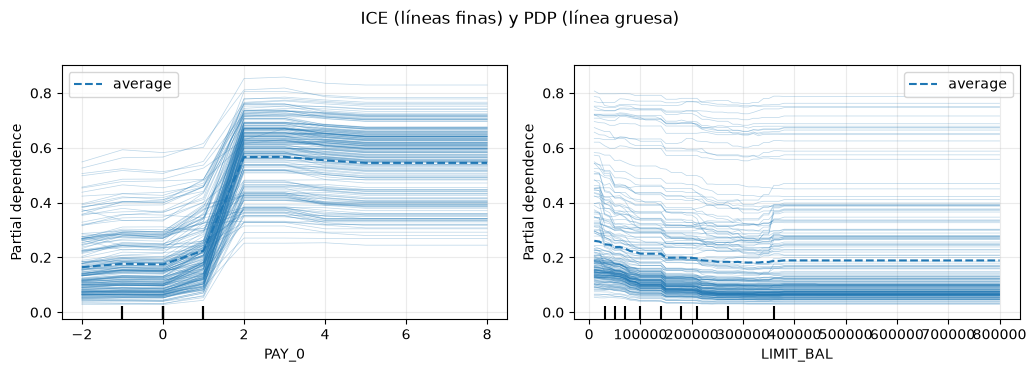

In [12]:
# PDP + ICE de las 2 variables más importantes: forma del efecto
top2 = ORDEN[:2]
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))

PartialDependenceDisplay.from_estimator(modelo, X_va.astype(float), top2, kind="both", subsample=200,
                                        random_state=SEMILLA, ax=ax)
fig.suptitle("ICE (líneas finas) y PDP (línea gruesa)", y=1.02)
guarda("04_pdp_ice"); plt.show()

**Como lo leo:** PAY_0 es con diferencia la variable que mas manda (mean|SHAP| de 0,48 frente a 0,16 de la segunda, LIMIT_BAL) y en el beeswarm se ve que los retrasos empujan el riesgo hasta mas de +2 en log-odds mientras que estar al dia lo baja poco. Despues vienen LIMIT_BAL, BILL_AMT1 y PAY_2, y luego los importes pagados (PAY_AMT1-4), donde pagar mas baja el riesgo y un limite mas alto tambien, aunque no lo leeria como causal porque el limite lo fija el propio banco segun lo que ya piensa del cliente. Ojo con la cola porque las 11 variables restantes suman 0,35, casi lo mismo que las tres siguientes juntas.

Los tres rankings se parecen bastante (Spearman de 0,79 entre SHAP y permutation, 0,88 entre SHAP y ganancia y 0,74 entre permutation y ganancia) y 4 de las 5 primeras coinciden entre SHAP y permutation (PAY_0, LIMIT_BAL, BILL_AMT1 y PAY_2, y la quinta es PAY_AMT3 o PAY_AMT1, que estan practicamente empatadas). Donde mas discrepan es en PAY_2, segunda por ganancia pero con poca caida de AUC en permutation, y mi hipotesis es que esta muy relacionada con PAY_0 y al barajar una el modelo se apoya en la otra, aunque no lo he comprobado. BILL_AMT1 sale tercera en SHAP y en permutation pero sin una direccion clara en el beeswarm, asi que sospecho que importa en relacion con el limite (cuanto de este usa el cliente), y eso lo pruebo en 6.

En el PDP de PAY_0 el riesgo se queda plano en torno a 0,17 hasta 0, sube un poco con 1 mes de retraso y salta a 0,57 con 2 meses para no cambiar mas, es decir que para el modelo 2 meses de retraso es lo mismo que 8, un escalon que encaja con que la logistica lo haga peor. En LIMIT_BAL el riesgo medio baja de 0,26 a 0,20 hasta los 150.000 y luego se queda plano, pero las ICE son muy distintas entre clientes (a algunos de riesgo alto el limite no les cambia nada) y por eso el PDP medio engaña un poco ahi. El salto raro cerca de 360.000 creo que es por falta de datos en esa zona y no un efecto real.

### 4.2 Local: ¿por qué a ESTE cliente?
Cojo tres casos de validación: un impago bien detectado (TP), un impago que el modelo no ve (FN) y una falsa alarma (FP).

TP (impago detectado)        fila  3630   P(impago) = 0.85   real = 1
FN (impago que se escapa)    fila   355   P(impago) = 0.03   real = 1
FP (falsa alarma)            fila  1180   P(impago) = 0.85   real = 0


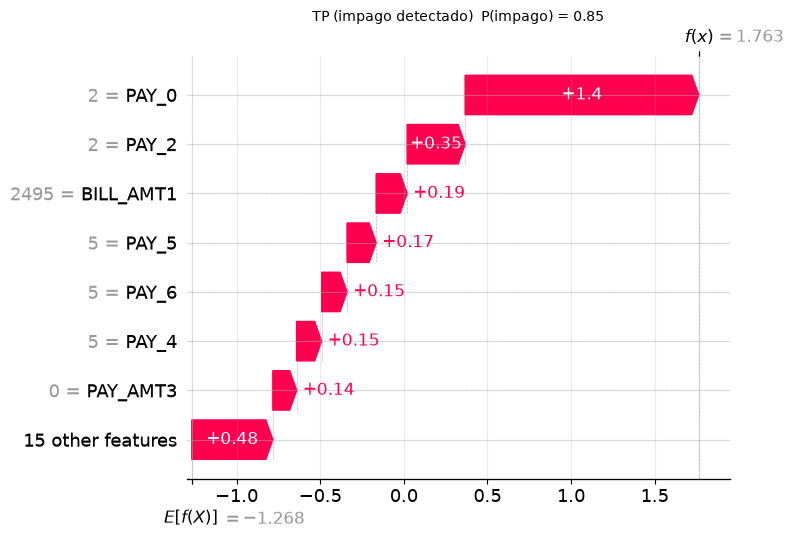

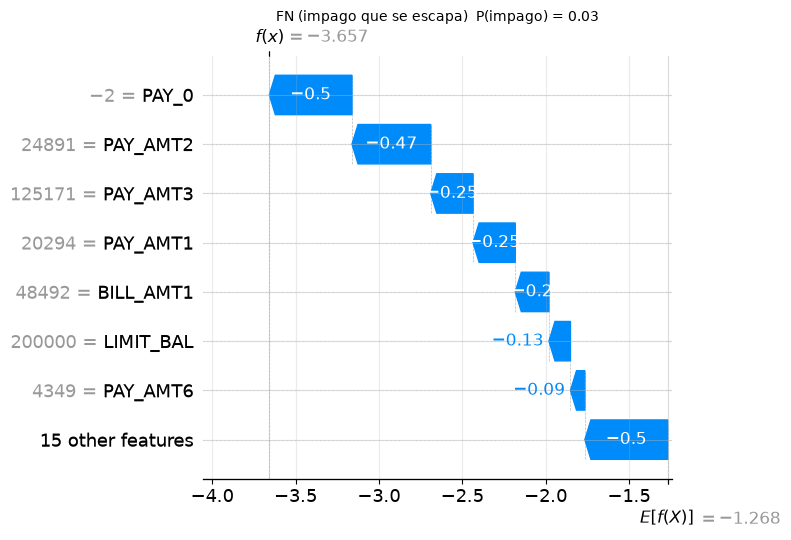

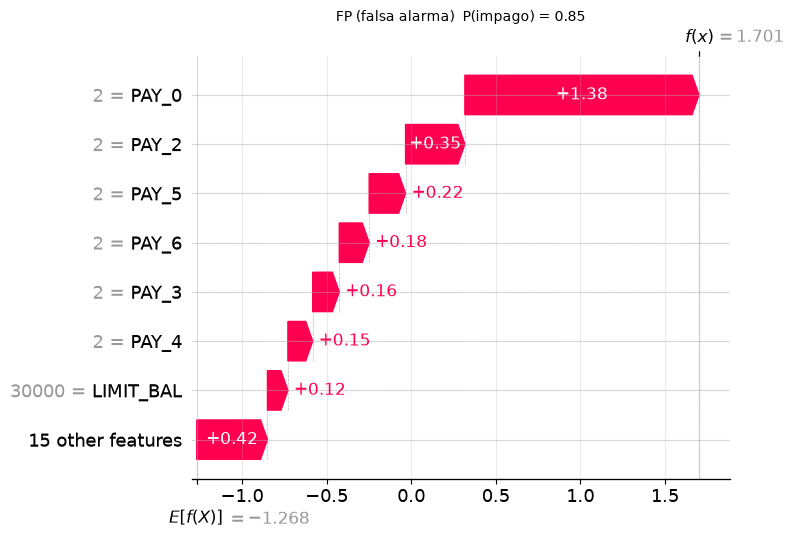

In [13]:
#Elijo los 3 casos
yv = y_va.values
pos = np.arange(len(yv))
i_tp = pos[(yv == 1) & (p_va >= UMBRAL)][np.argmax(p_va[(yv == 1) & (p_va >= UMBRAL)])]   # impago detectado con más seguridad
i_fn = pos[(yv == 1) & (p_va < UMBRAL)][np.argmin(p_va[(yv == 1) & (p_va < UMBRAL)])]     # impago que más se nos escapa
i_fp = pos[(yv == 0) & (p_va >= UMBRAL)][np.argmax(p_va[(yv == 0) & (p_va >= UMBRAL)])]   # falsa alarma más clara
casos = {"TP (impago detectado)": i_tp, "FN (impago que se escapa)": i_fn, "FP (falsa alarma)": i_fp}
for nom, i in casos.items():
    print(f"{nom:28s} fila {i:5d}   P(impago) = {p_va[i]:.2f}   real = {yv[i]}")

for nom, i in casos.items():
    plt.figure(); shap.plots.waterfall(sv[i], max_display=8, show=False)
    plt.title(f"{nom}  P(impago) = {p_va[i]:.2f}", fontsize=10)
    guarda("05_waterfall_" + nom.split()[0].lower()); plt.show()

In [14]:
# LIME en los mismos casos y comparación con SHAP
from lime.lime_tabular import LimeTabularExplainer
lime_exp = LimeTabularExplainer(X_tr.values, feature_names=FEATS, class_names=["paga", "impago"],
                                mode="classification", discretize_continuous=True, random_state=SEMILLA)

def top_lime(i, k=5, n=1500):
    e = lime_exp.explain_instance(X_va.iloc[i].values, modelo.predict_proba, num_features=k, num_samples=n, labels=(1,))
    return [FEATS[j] for j, _ in e.as_map()[1]]

def top_shap(i, k=5):
    return [FEATS[j] for j in np.argsort(-np.abs(sv.values[i]))[:k]]

filas = []
for nom, i in casos.items():
    a, b = top_shap(i), top_lime(i)
    filas.append({"caso": nom, "top-5 SHAP": ", ".join(a), "top-5 LIME": ", ".join(b), "coinciden": len(set(a) & set(b))})
display(pd.DataFrame(filas))

,caso,top-5 SHAP,top-5 LIME,coinciden
0,TP (impago detectado),"PAY_0, PAY_2, BILL_AMT1, PAY_5, PAY_6","PAY_0, LIMIT_BAL, PAY_3, PAY_2, PAY_AMT2",2
1,FN (impago que se escapa),"PAY_0, PAY_AMT2, PAY_AMT3, PAY_AMT1, BILL_AMT1","PAY_0, PAY_AMT2, BILL_AMT4, LIMIT_BAL, PAY_AMT1",3
2,FP (falsa alarma),"PAY_0, PAY_2, PAY_5, PAY_6, PAY_3","PAY_0, LIMIT_BAL, PAY_5, PAY_3, PAY_2",4


In [15]:
# "Qué pasaría si": contrafactual con un cliente señalado como riesgo --> he decidido no usar librerias y mirar a mano y cambiar para asi ver si baja la probabilidad de impago
cand = pos[(p_va >= UMBRAL) & (p_va < UMBRAL + 0.30) & (X_va["PAY_0"].values > 0)]  
i_cf = cand[np.argmin(p_va[cand])] if len(cand) else i_tp
cliente = X_va.iloc[[i_cf]].copy()
print(f"Cliente {i_cf}: P(impago) = {p_va[i_cf]:.2f}  (umbral de decisión = {UMBRAL:.2f})")
print(cliente[["LIMIT_BAL", "PAY_0", "PAY_2", "BILL_AMT1", "PAY_AMT1"]].to_string(index=False))

def prob_si(**cambios):
    c = cliente.copy()
    for col, f in cambios.items():
        c[col] = f(c[col])
    return float(modelo.predict_proba(c)[:, 1][0])

escenarios = {
    "tal cual": prob_si(),
    "paga el doble cada mes (PAY_AMT x2)": prob_si(**{c: (lambda s: s * 2) for c in PAYAMT}),
    "paga 5 veces más (PAY_AMT x5)": prob_si(**{c: (lambda s: s * 5) for c in PAYAMT}),
    "debe la mitad (BILL_AMT x0.5)": prob_si(**{c: (lambda s: s * 0.5) for c in BILL}),
    "hubiera pagado a tiempo el último mes (PAY_0 = 0)": prob_si(PAY_0=lambda s: 0),
}
for k, v in escenarios.items():
    print(f"{k:50s} P(impago) = {v:.2f}  {'-> ya NO lo marcaría' if v < UMBRAL else '-> sigue marcado'}")
RES["what_if"] = escenarios

Cliente 5817: P(impago) = 0.27  (umbral de decisión = 0.27)
 LIMIT_BAL  PAY_0  PAY_2  BILL_AMT1  PAY_AMT1
    130000      1      2      99290         0
tal cual                                           P(impago) = 0.27  -> sigue marcado
paga el doble cada mes (PAY_AMT x2)                P(impago) = 0.25  -> ya NO lo marcaría
paga 5 veces más (PAY_AMT x5)                      P(impago) = 0.15  -> ya NO lo marcaría
debe la mitad (BILL_AMT x0.5)                      P(impago) = 0.26  -> ya NO lo marcaría
hubiera pagado a tiempo el último mes (PAY_0 = 0)  P(impago) = 0.16  -> ya NO lo marcaría


In [16]:
# Mismo what-if pero con un cliente de riesgo alto (el TP), para ver si las acciones "reales" bastan
cliente = X_va.iloc[[i_tp]].copy()
print("tal cual:", round(prob_si(), 2))
print("paga 5 veces mas:", round(prob_si(**{c: (lambda s: s * 5) for c in PAYAMT}), 2))
print("debe la mitad:   ", round(prob_si(**{c: (lambda s: s * 0.5) for c in BILL}), 2))
print("PAY_0 = 0:       ", round(prob_si(PAY_0=lambda s: 0), 2))

tal cual: 0.85
paga 5 veces mas: 0.85
debe la mitad:    0.79
PAY_0 = 0:        0.59


In [17]:
print(cliente[PAYAMT].to_string(index=False))
print("paga 20.000 al mes:", round(prob_si(**{c: (lambda s: s + 20000) for c in PAYAMT}), 2))

 PAY_AMT1  PAY_AMT2  PAY_AMT3  PAY_AMT4  PAY_AMT5  PAY_AMT6
        0         0         0         0         0         0
paga 20.000 al mes: 0.66


**Como lo leo:** en el TP (fila 3630, P = 0,85) casi todo lo pone PAY_0 = 2 (+1,4 en log-odds) y PAY_2 = 2 (+0,35), con aportes menores de los retrasos antiguos (PAY_4-6 = 5). Me llama la atencion que `BILL_AMT1` sea baja (2.495) y aun asi sume riesgo (+0,19), al reves de lo que diria "mas deuda, mas riesgo", asi que su efecto debe depender del resto del cliente. En el FN (fila 355, P = 0,03) todo empuja hacia abajo (PAY_0 = -2, pagos grandes, limite de 200.000) y el cliente impago igualmente, o sea que la explicacion me dice por que el modelo estaba tan seguro pero no por que se equivoco, y lo mas probable es que falte informacion que no esta en los datos. El FP (fila 1180, P = 0,85) es casi igual que el TP (2 meses de retraso en los seis meses) y no impago, y eso es lo mas incomodo: dos clientes con la misma explicacion y distinto resultado, que es el limite de lo que se puede sacar con estas variables.

LIME y SHAP coinciden en que PAY_0 es la primera en los tres casos, pero en el resto del top-5 solo comparten 2, 3 y 4 de 5 variables (TP, FN y FP). LIME mete LIMIT_BAL y BILL_AMT4 donde SHAP pone otras, lo cual tiene sentido porque LIME ajusta un modelo lineal local sobre perturbaciones discretizadas y SHAP reparte exactamente la prediccion del arbol, asi que no hay una "verdad" para decidir cual vale mas (con 30 clientes lo cuantifico en §5).

En el "que pasaria si" elegi un cliente justo por encima del umbral (fila 5817, P = 0,27) asi que cualquier cambio pequeño ya lo saca de la lista: pagar el doble lo deja en 0,25, deber la mitad en 0,26, pagar 5 veces mas en 0,15 y haber pagado a tiempo el ultimo mes en 0,16. Ojo porque PAY_AMT1 era 0 y el "x2" solo toca los otros meses, y porque es un contrafactual casero que cambia variables sueltas (pagar 5 veces mas deberia bajar tambien la factura).

Con un cliente de riesgo alto (el TP, P = 0,85) el panorama es otro. Tiene los seis PAY_AMT a 0, asi que el "x5" no cambia nada (0 x 5 = 0) y lo tuve que probar con un pago fijo: pagar 20.000 al mes lo baja a 0,66, deber la mitad a 0,79 y haber pagado a tiempo el ultimo mes (PAY_0 = 0) a 0,59, y ninguna lo saca de la lista (umbral de 0,27) porque el resto del historial (PAY_2 y los meses antiguos) sigue empujando hacia arriba. O sea que las acciones solo le dan la vuelta al modelo cuando el cliente ya esta cerca del umbral, y en los de riesgo alto manda un historial que ya no se puede cambiar. Aun asi son pruebas sueltas y hechas a mano (una variable cada vez y con cantidades que me invento), asi que lo tomo como una pista y no como una conclusion.

## 5. ¿Me puedo fiar de las explicaciones? (sanity checks)

Una explicación es un *modelo del modelo*, y puede estar mal. Hago cinco comprobaciones:
1. **Aditividad de SHAP:** base + suma de SHAP tiene que ser igual a la salida del modelo.
2. **Aleatorizar etiquetas:** si entreno con las y barajadas, las explicaciones tienen que cambiar por completo (Adebayo et al., 2018).
3. **Romper las variables "importantes":** barajo las top-k y miro cuánto cae el AUC, frente a barajar k variables al azar (sin reentrenar).
4. **Acuerdo SHAP vs LIME** en muchos clientes, no solo tres.
5. **Estabilidad:** reentreno con remuestreos (bootstrap) y miro si el ranking de SHAP se mantiene.

In [18]:
resumen_tests = {}

# 1) Aditividad
raw = modelo.predict(X_va, output_margin=True)
err = float(np.max(np.abs(raw - (np.ravel(sv.base_values) + sv.values.sum(axis=1)))))
print(f"1) Aditividad: error máximo = {err:.2e}  (debería ser ~0)")
resumen_tests["aditividad (error máx.)"] = err

# 2) Etiquetas barajadas: mismo modelo, mismas variables, pero y aleatoria
y_alea = np.random.default_rng(SEMILLA).permutation(y_tr.values)
m_alea = xgb_fijo(CFG).fit(X_tr, y_alea)
auc_alea = roc_auc_score(y_va, m_alea.predict_proba(X_va)[:, 1])
imp_alea = pd.Series(np.abs(shap.TreeExplainer(m_alea)(X_va).values).mean(axis=0), index=FEATS)
rho_alea = spearmanr(imp_shap, imp_alea)[0]
print(f"2) Etiquetas barajadas: AUC val = {auc_alea:.3f} (≈0.5 esperado) | Spearman ranking real vs aleatorio = {rho_alea:.2f} (≈0 esperado)")
resumen_tests["etiquetas barajadas: AUC / Spearman"] = [round(float(auc_alea), 3), round(float(rho_alea), 2)]

1) Aditividad: error máximo = 2.62e-06  (debería ser ~0)
2) Etiquetas barajadas: AUC val = 0.461 (≈0.5 esperado) | Spearman ranking real vs aleatorio = 0.05 (≈0 esperado)


,caída AUC (top-k SHAP),caída AUC (k al azar)
k,,
1,0.0755,0.0069
2,0.0946,0.0211
3,0.1015,0.0197
4,0.1220,0.0102
5,0.1312,0.0285


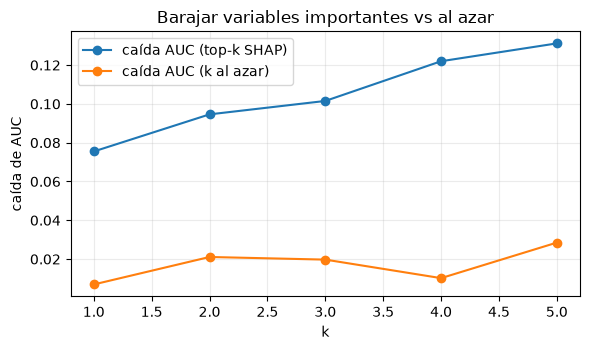

In [20]:
# 3) Barajar las top-k variables según SHAP vs k variables al azar (sin reentrenar)
auc_base = roc_auc_score(y_va, p_va)

def auc_barajando(cols, rep=3):
    out = []
    for r in range(rep):
        rg = np.random.default_rng(r); Xp = X_va.copy()
        for c in cols:
            Xp[c] = rg.permutation(Xp[c].values)
        out.append(roc_auc_score(y_va, modelo.predict_proba(Xp)[:, 1]))
    return np.mean(out)

rg = np.random.default_rng(SEMILLA); filas = []
for k in range(1, 6):
    caida_shap = auc_base - auc_barajando(ORDEN[:k])
    caida_azar = np.mean([auc_base - auc_barajando(list(rg.choice(FEATS, k, replace=False)), rep=1)
                          for _ in range(15)])
    filas.append({"k": k, "caída AUC (top-k SHAP)": caida_shap, "caída AUC (k al azar)": caida_azar})
t3 = pd.DataFrame(filas).set_index("k"); display(t3.round(4))
resumen_tests["barajar top-5: caída AUC (SHAP vs azar)"] = [round(float(t3.loc[5].iloc[0]), 4), round(float(t3.loc[5].iloc[1]), 4)]

t3.plot(marker="o", figsize=(6, 3.6)); plt.ylabel("caída de AUC"); plt.title("Barajar variables importantes vs al azar")
guarda("06_barajar_topk"); plt.show()

In [21]:
# 4) Acuerdo SHAP vs LIME en varios clientes de validación (top-3 en común)
N_LIME = 30
idx = np.random.default_rng(SEMILLA).choice(len(X_va), N_LIME, replace=False)
solape = [len(set(top_shap(i, 3)) & set(top_lime(i, 3, n=1000))) / 3 for i in idx]
print(f"4) Solape medio top-3 SHAP vs LIME en {N_LIME} clientes: {np.mean(solape):.2f}")
resumen_tests["acuerdo SHAP-LIME (top-3)"] = round(float(np.mean(solape)), 2)

# 5) Estabilidad de SHAP con bootstrap (reentrenando)
NB = 4
sub = X_va.iloc[:2000]
imp0 = np.abs(shap.TreeExplainer(modelo)(sub).values).mean(axis=0)
rhos, solapes = [], []
for b in range(NB):
    ib = np.random.default_rng(100 + b).integers(0, len(X_tr), len(X_tr))
    mb = xgb_fijo(CFG).fit(X_tr.iloc[ib], y_tr.iloc[ib])
    impb = np.abs(shap.TreeExplainer(mb)(sub).values).mean(axis=0)
    rhos.append(spearmanr(imp0, impb)[0])
    solapes.append(len(set(np.argsort(-imp0)[:5]) & set(np.argsort(-impb)[:5])) / 5)
print(f"5) Estabilidad con {NB} reentrenos bootstrap: Spearman medio = {np.mean(rhos):.2f} | solape top-5 = {np.mean(solapes):.2f}")
resumen_tests["estabilidad bootstrap (Spearman / top-5)"] = [round(float(np.mean(rhos)), 2), round(float(np.mean(solapes)), 2)]

RES["sanity_checks"] = resumen_tests
print("\nResumen:"); [print(" -", k, ":", v) for k, v in resumen_tests.items()];

4) Solape medio top-3 SHAP vs LIME en 30 clientes: 0.64
5) Estabilidad con 4 reentrenos bootstrap: Spearman medio = 0.82 | solape top-5 = 0.90

Resumen:
 - aditividad (error máx.) : 2.6226043701171875e-06
 - etiquetas barajadas: AUC / Spearman : [0.461, 0.05]
 - barajar top-5: caída AUC (SHAP vs azar) : [0.1312, 0.0285]
 - acuerdo SHAP-LIME (top-3) : 0.64
 - estabilidad bootstrap (Spearman / top-5) : [0.82, 0.9]


**Como lo leo:** los cinco tests salen razonables. La aditividad se cumple (error de 2,6e-6) y con las etiquetas barajadas el modelo no aprende nada (AUC de 0,46) y el ranking de SHAP no se parece al real (Spearman de 0,05), asi que SHAP si "ve" el modelo y no es un artefacto. Barajar las 5 variables mas importantes segun SHAP baja el AUC en 0,13 (de 0,79 a 0,66) frente a solo 0,03 al barajar 5 al azar, y la curva del azar no es monotona porque es una media que depende de si en el sorteo cae PAY_0.

Lo mas flojo es el acuerdo con LIME, con un solape medio del top-3 de 0,64 en 30 clientes, o sea que discrepan en una de cada tres variables, asi que lo trato como una explicacion complementaria y no como una confirmacion. La estabilidad es mejor: con 4 reentrenos bootstrap el Spearman medio es 0,82 y el top-5 se repite en un 90 %, por lo que me fio de las primeras posiciones del ranking y bastante menos de las bajas.

## 6. Uso accionable 4.1: mejorar el modelo con lo que dicen las explicaciones

Pistas que he visto en 2 y 4:
- BILL_AMT2..6 estan muy correlacionadas con BILL_AMT1 (0,89 de media en 2) y por separado aportan poco en SHAP (menos de 0,05 cada una) -> candidatas a eliminar por redundantes, aunque con variables tan correlacionadas SHAP reparte la importancia entre ellas, asi que lo compruebo quitandolas y mirando el AUC. BILL_AMT1 si importa (tercera en SHAP y en permutation) y la mantengo.
- El modelo vive del historial de pagos (PAY_0 con 0,48 de mean|SHAP|) y los datos no traen variables ya resumidas, asi que pruebo a crear features nuevas que lo resuman: utilizacion del limite (lo que capta BILL_AMT1 junto a LIMIT_BAL), cuanto paga de lo que debe (los PAY_AMT altos bajan el riesgo), numero de meses con retraso y retraso maximo (PAY_2, PAY_3 y PAY_5 tambien empujan al alza).

Pruebo tres versiones con el mismo modelo y protocolo, y comparo antes/despues en test con un bootstrap pareado. Las dos ideas son hipotesis y el resultado puede ser que no mejoren nada, lo cual tambien me sirve.

In [22]:
# Features nuevas (solo usan datos de la propia fila, así que no hay fuga de información)
def con_features_nuevas(Xd):
    Xd = Xd.copy()
    Xd["UTIL_1"] = (Xd["BILL_AMT1"] / Xd["LIMIT_BAL"]).clip(-1, 3)                 # cuánto del límite está usando
    Xd["RATIO_PAGO_1"] = (Xd["PAY_AMT1"] / Xd["BILL_AMT1"].clip(lower=1)).clip(0, 5)   # qué parte de la factura paga
    Xd["N_MESES_RETRASO"] = (Xd[PAY] > 0).sum(axis=1)
    Xd["MAX_RETRASO"] = Xd[PAY].max(axis=1)
    return Xd

sin_facturas = [c for c in FEATS if c not in BILL[1:]]            # quito BILL_AMT2..6
variantes = {
    "Base":                      (X_tr[FEATS], X_va[FEATS], X_te[FEATS]),
    "A: sin BILL_AMT2..6":       (X_tr[sin_facturas], X_va[sin_facturas], X_te[sin_facturas]),
    "B: A + features nuevas":    tuple(con_features_nuevas(Z[sin_facturas]) for Z in (X_tr, X_va, X_te)),
}

rg = np.random.default_rng(SEMILLA); BB = 1000
idx_boot = [rg.integers(0, len(y_te), len(y_te)) for _ in range(BB)]   

modelos_v, p_te_v, filas = {}, {}, []
for nom, (a, b, c) in variantes.items():
    m = entrena_xgb(CFG, a, y_tr, b, y_va)
    pv, pt = m.predict_proba(b)[:, 1], m.predict_proba(c)[:, 1]
    modelos_v[nom], p_te_v[nom] = m, pt
    filas.append({"variante": nom, "nº features": a.shape[1], "AUC val": roc_auc_score(y_va, pv),
                  "AUC test": roc_auc_score(y_te, pt), "PR-AUC test": average_precision_score(y_te, pt),
                  "Brier test": brier_score_loss(y_te, pt)})
tv = pd.DataFrame(filas).set_index("variante")

# Diferencia de AUC en test respecto a la base, con IC (bootstrap pareado)
for nom in variantes:
    d = [roc_auc_score(y_te.values[i], p_te_v[nom][i]) - roc_auc_score(y_te.values[i], p_te_v["Base"][i]) for i in idx_boot]
    tv.loc[nom, "Δ AUC test vs base"] = np.mean(d)
    tv.loc[nom, "IC95% Δ"] = f"[{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]"
display(tv.round(4))
RES["mejora_modelo"] = tv.round(4).astype(str).to_dict()

,nº features,AUC val,AUC test,PR-AUC test,Brier test,Δ AUC test vs base,IC95% Δ
variante,,,,,,,
Base,22,0.7866,0.7731,0.5548,0.1356,0.0000,"[+0.0000, +0.0000]"
A: sin BILL_AMT2..6,17,0.7867,0.7735,0.5553,0.1357,0.0004,"[-0.0016, +0.0024]"
B: A + features nuevas,21,0.7902,0.7770,0.5565,0.1354,0.0039,"[+0.0006, +0.0072]"


,Base (top-8),Variante B (top-8)
0,PAY_0,PAY_0
1,LIMIT_BAL,MAX_RETRASO
2,BILL_AMT1,N_MESES_RETRASO
3,PAY_2,BILL_AMT1
4,PAY_AMT3,UTIL_1
5,PAY_AMT1,LIMIT_BAL
6,PAY_AMT2,PAY_AMT3
7,PAY_AMT4,PAY_AMT2


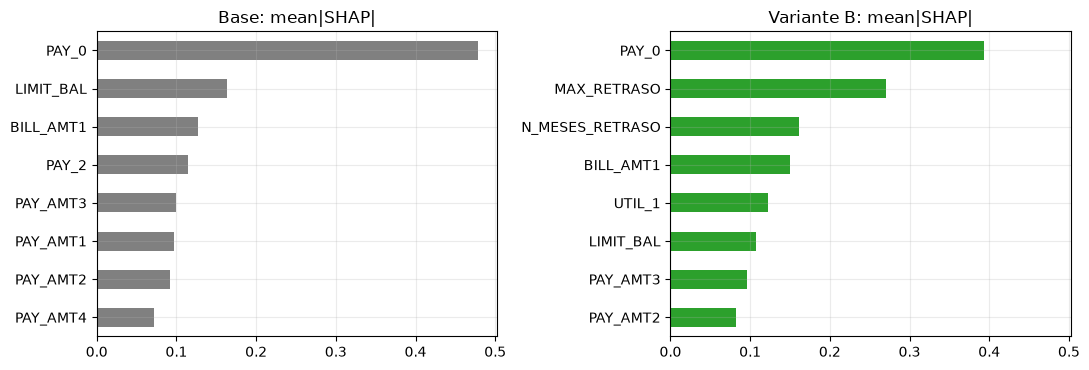

In [23]:
# ¿Cambia lo que el modelo considera importante? SHAP antes vs después
sv_b = shap.TreeExplainer(modelos_v["B: A + features nuevas"])(variantes["B: A + features nuevas"][1])
imp_b = pd.Series(np.abs(sv_b.values).mean(axis=0), index=variantes["B: A + features nuevas"][1].columns).sort_values(ascending=False)
comp = pd.DataFrame({"Base (top-8)": imp_shap.sort_values(ascending=False).head(8).index.tolist(),
                     "Variante B (top-8)": imp_b.head(8).index.tolist()})
display(comp)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
imp_shap.sort_values().tail(8).plot.barh(ax=ax[0], color="gray"); ax[0].set_title("Base: mean|SHAP|")
imp_b.sort_values().tail(8).plot.barh(ax=ax[1], color="tab:green"); ax[1].set_title("Variante B: mean|SHAP|")
guarda("07_shap_antes_despues"); plt.show()

**Como lo leo:** quitar las facturas BILL_AMT2..6 no cambia nada (el AUC de test pasa de 0,7731 a 0,7735 y el IC del Δ, [-0,0016, +0,0024], contiene el 0), asi que me quedo con 5 variables menos sin perder rendimiento y eso confirma que eran redundantes. Con las features nuevas (variante B) el AUC de test sube a 0,7770, un Δ de +0,0039 con IC [+0,0006, +0,0072], que no contiene el 0 pero queda muy justo, y el PR-AUC y el Brier casi no se mueven, asi que la mejora es real pero pequeña y en la practica no cambiaria gran cosa. Tiene sentido porque los arboles ya podian combinar los PAY_* por su cuenta, y hay que tener en cuenta que el bootstrap pareado solo recoge la variabilidad del test y no la del entrenamiento.

Mirando el SHAP, las features nuevas entran enseguida (MAX_RETRASO y N_MESES_RETRASO son la 2ª y la 3ª, y UTIL_1 la 5ª) mientras PAY_0 baja de 0,48 a 0,39 y PAY_2 sale del top-8, pero eso no quiere decir que importen menos, sino que las variables derivadas se reparten el credito con las originales. LIMIT_BAL baja de 0,16 a 0,11 con UTIL_1 presente, asi que la utilizacion absorbe parte de su papel, pero BILL_AMT1 no baja (sube a 0,15), por lo que mi sospecha de que captaba la utilizacion solo se cumple a medias.

## 7. Uso accionable 4.2: insights de negocio

,P(impago) predicha,impago observado,n
0,0.049,0.045,600
1,0.074,0.072,599
2,0.092,0.098,599
3,0.111,0.119,599
4,0.132,0.180,600
5,0.156,0.127,599
6,0.195,0.185,599
7,0.263,0.264,599
8,0.415,0.424,599
9,0.706,0.698,600


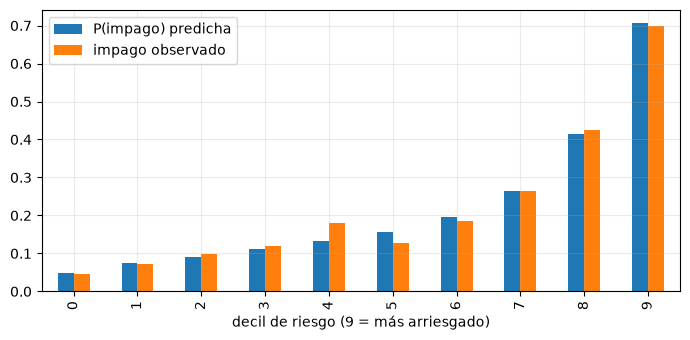

El 10 % más arriesgado impaga 3.2 veces más que la media.


In [24]:
# ¿Está bien ordenado el riesgo? Deciles de riesgo predicho en test
dec = pd.qcut(pd.Series(p_te).rank(method="first"), 10, labels=False)
tab_dec = pd.DataFrame({"P(impago) predicha": pd.Series(p_te).groupby(dec).mean(),
                        "impago observado": y_te.reset_index(drop=True).groupby(dec).mean(), "n": pd.Series(p_te).groupby(dec).size()})
display(tab_dec.round(3))
ax = tab_dec[["P(impago) predicha", "impago observado"]].plot.bar(figsize=(7, 3.5)); ax.set_xlabel("decil de riesgo (9 = más arriesgado)")
guarda("08_deciles"); plt.show()
top_dec = tab_dec["impago observado"].iloc[-1] / df["default"].mean()
print(f"El 10 % más arriesgado impaga {top_dec:.1f} veces más que la media.")
RES["decil_top_lift"] = float(top_dec)

In [ ]:
#¿Dónde pongo el umbral? Depende del coste de equivocarse
#Un impago no detectado (FN) cuesta "r" veces más que una falsa alarma (FP), los costes son un supuesto y se podrian cambiar dependiendo del banco. 
y_v, y_t = y_va.values, y_te.values
n_pos, n_neg = y_t.sum(), (1 - y_t).sum()
filas = []
for r in [2, 5, 10]:
    grid = np.arange(0.02, 0.9, 0.01)
    coste_val = [(r * ((p_va < t) & (y_v == 1)).sum() + ((p_va >= t) & (y_v == 0)).sum()) / len(y_v) for t in grid]
    t_opt = grid[int(np.argmin(coste_val))]
    pred = p_te >= t_opt
    coste = (r * ((~pred) & (y_t == 1)).sum() + (pred & (y_t == 0)).sum()) / len(y_t)
    filas.append({"coste FN:FP": f"{r}:1", "umbral óptimo (val)": t_opt, "coste/cliente con modelo": coste,
                  "aprobar a todos": r * n_pos / len(y_t), "rechazar a todos": n_neg / len(y_t),
                  "% marcado como riesgo": pred.mean()})
pol = pd.DataFrame(filas).set_index("coste FN:FP"); display(pol.round(3))
RES["politica_coste"] = pol.round(4).astype(str).to_dict()

,umbral óptimo (val),coste/cliente con modelo,aprobar a todos,rechazar a todos,% marcado como riesgo
coste FN:FP,,,,,
2:1,0.27,0.313,0.443,0.779,0.241
5:1,0.18,0.555,1.106,0.779,0.379
10:1,0.09,0.718,2.213,0.779,0.761


In [27]:
# ¿El modelo se fija en cosas distintas según el tipo de cliente? SHAP por segmento
en_mora = (X_va["PAY_0"] > 0).values
seg = pd.DataFrame({"ya con retraso (PAY_0>0)": np.abs(sv.values[en_mora]).mean(axis=0),
                    "al día (PAY_0<=0)": np.abs(sv.values[~en_mora]).mean(axis=0)}, index=FEATS)
display(seg.loc[ORDEN[:8]].round(3))
print(f"Clientes con retraso: {en_mora.mean():.0%} | tasa de impago real: {y_va[en_mora].mean():.0%} vs {y_va[~en_mora].mean():.0%} en los que están al día")

print(y_va[~en_mora].sum() / y_va.sum())

,ya con retraso (PAY_0>0),al día (PAY_0<=0)
PAY_0,0.722,0.408
LIMIT_BAL,0.123,0.175
BILL_AMT1,0.101,0.134
PAY_2,0.260,0.072
PAY_AMT3,0.096,0.101
PAY_AMT1,0.100,0.096
PAY_AMT2,0.068,0.099
PAY_AMT4,0.059,0.076


Clientes con retraso: 23% | tasa de impago real: 50% vs 14% en los que están al día
0.48491704374057315


**Como lo leo**: el riesgo esta bien ordenado y bien calibrado por deciles, porque la probabilidad predicha y el impago observado casi coinciden en todos (4,9 % frente a 4,5 % en el decil mas bajo y 70,6 % frente a 69,8 % en el mas alto), con algo de desorden en los deciles 4 y 5 que atribuyo a ruido (unos 600 clientes por decil). El 10 % mas arriesgado impaga 3,2 veces mas que la media, asi que el modelo sirve para clasificar clientes en bandas de riesgo y no solo para decir si/no.

El umbral no es algo tecnico sino una decision de negocio y cambia mucho con el coste relativo de un impago no detectado frente a una falsa alarma (costes que son un supuesto mio, no datos del banco). Con 2:1 el umbral optimo es 0,27, marca al 24 % de clientes y el coste por cliente baja de 0,44 (aprobar a todos) a 0,31, un 29 % menos; con 5:1 baja a 0,18, marca al 38 % y el coste (0,56) es un 29 % menor que rechazar a todos (0,78); pero con 10:1 el umbral cae a 0,09, se marca al 76 % de los clientes y el coste (0,72) es casi igual que rechazar a todos (0,78), o sea que si equivocarse en un impago cuesta tanto el modelo apenas aporta nada.

Por segmentos, el 23 % de los clientes ya tiene retraso y de ellos impaga el 50 %, frente al 14 % de los que van al dia. En los morosos el modelo casi solo lee el historial (PAY_0 con 0,72 y PAY_2 con 0,26), mientras que en los que van al dia el riesgo depende mas de LIMIT_BAL, BILL_AMT1 y los importes pagados (PAY_AMT), con un peso de PAY_2 mucho menor (0,07). Esto importa porque,casi la mitad de los impagos (el 48.5 %) salen de clientes que van al dia, que son justo los que tienen señales mas debiles, asi que lo logico seria tratarlos con politicas distintas, con cobro y renegociacion para los morosos y vigilancia de la utilizacion del limite y de los pagos para los que van al dia.

## 8. Uso accionable 4.3: equidad y sesgos

Aunque SEX no entra como variable, el modelo puede tratar distinto a hombres y mujeres (por proxies, o simplemente porque las tasas base cambian).
Audito por sexo y por tramo de edad en test con el umbral fijado antes. En UCI: SEX 1 = hombre, 2 = mujer (solo hay esas dos categorías en el dataset).

In [28]:
#Auditoría por grupos
def auditoria(grupo, p, t=UMBRAL):
    filas = []
    for g in sorted(pd.unique(grupo)):
        m = (grupo == g).values; yy, pp = y_t[m], p[m]; flag = pp >= t
        filas.append({"grupo": g, "n": int(m.sum()), "impago real": yy.mean(), "% marcados": flag.mean(),
                      "TPR (recall)": flag[yy == 1].mean(), "FPR": flag[yy == 0].mean(), "AUC": roc_auc_score(yy, pp)})
    return pd.DataFrame(filas).set_index("grupo")

edad_te = pd.cut(X_te["AGE"], [0, 29, 39, 49, 120], labels=["<30", "30-39", "40-49", "50+"]).astype(str)
aud_sexo, aud_edad = auditoria(sexo_te, p_te), auditoria(edad_te, p_te)
print("=== Por sexo ==="); display(aud_sexo.round(3))
print("=== Por edad ==="); display(aud_edad.round(3))
gap = lambda a, c: float(a[c].max() - a[c].min())
print(f"Brechas por sexo -> %marcados: {gap(aud_sexo, '% marcados'):.3f} | TPR: {gap(aud_sexo, 'TPR (recall)'):.3f} | FPR: {gap(aud_sexo, 'FPR'):.3f}")
RES["auditoria_sexo"] = aud_sexo.round(4).astype(str).to_dict()

=== Por sexo ===


,n,impago real,% marcados,TPR (recall),FPR,AUC
grupo,,,,,,
hombre,2332,0.244,0.264,0.545,0.174,0.754
mujer,3661,0.207,0.226,0.568,0.137,0.786


=== Por edad ===


,n,impago real,% marcados,TPR (recall),FPR,AUC
grupo,,,,,,
30-39,2208,0.208,0.211,0.517,0.130,0.766
40-49,1298,0.233,0.246,0.558,0.151,0.777
50+,560,0.259,0.289,0.648,0.164,0.792
<30,1927,0.217,0.257,0.572,0.170,0.772


Brechas por sexo -> %marcados: 0.038 | TPR: 0.023 | FPR: 0.037


In [29]:
# ¿Usa el modelo cosas distintas para cada sexo? ¿Y se puede adivinar el sexo con el resto de variables (proxy)?
seg_sexo = pd.DataFrame({f"SEX={g}": np.abs(sv.values[(sexo_va == g).values]).mean(axis=0) for g in sorted(sexo_va.unique())}, index=FEATS)
display(seg_sexo.loc[ORDEN[:6]].round(3))

# Proxy: intento predecir SEX solo con las demás variables (AUC ~0.5 = no hay proxy; alto = el sexo "se cuela")
n_p = 10000
ps = cross_val_predict(HistGradientBoostingClassifier(max_depth=3, random_state=SEMILLA), X_tr.iloc[:n_p],
                       (X.loc[X_tr.index[:n_p], "SEX"] == 2).astype(int), cv=3, method="predict_proba")[:, 1]
auc_proxy = roc_auc_score((X.loc[X_tr.index[:n_p], "SEX"] == 2).astype(int), ps)
print(f"AUC prediciendo SEX con el resto de variables: {auc_proxy:.3f}   (0.5 = no se puede)")
RES["proxy_auc_sex"] = auc_proxy

,SEX=hombre,SEX=mujer
PAY_0,0.490,0.471
LIMIT_BAL,0.170,0.158
BILL_AMT1,0.127,0.127
PAY_2,0.123,0.109
PAY_AMT3,0.096,0.103
PAY_AMT1,0.096,0.098


AUC prediciendo SEX con el resto de variables: 0.642   (0.5 = no se puede)


In [30]:
# Mitigación sencilla (post-procesado a lo Hardt et al. 2016): un umbral por sexo para igualar el recall
# Idea: en vez de un umbral global, elijo para cada grupo el umbral que da el mismo recall (TPR) que el global, usando VALIDACIÓN.
tpr_objetivo = ((p_va >= UMBRAL)[yv == 1]).mean()
umbral_g = {str(g): float(np.quantile(p_va[(sexo_va.values == g) & (yv == 1)], 1 - tpr_objetivo)) for g in sorted(sexo_va.unique())}
print("Umbrales por sexo:", {g: round(t, 3) for g, t in umbral_g.items()}, "| umbral global:", round(UMBRAL, 3))

pred_mit = np.array([p_te[i] >= umbral_g[s] for i, s in enumerate(sexo_te.values)])
def resumen(pred, nombre):
    fil = {}
    for g in sorted(sexo_te.unique()):
        m = (sexo_te == g).values
        fil[g] = (pred[m].mean(), pred[m][y_t[m] == 1].mean(), pred[m][y_t[m] == 0].mean())
    r = pd.DataFrame(fil, index=["% marcados", "TPR", "FPR"]).T
    print(f"--- {nombre} ---"); display(r.round(3))
    print(f"brecha TPR = {r['TPR'].max()-r['TPR'].min():.3f} | brecha FPR = {r['FPR'].max()-r['FPR'].min():.3f} | "
          f"F1 = {f1_score(y_t, pred):.3f} | precisión = {precision_score(y_t, pred):.3f}")
resumen(p_te >= UMBRAL, "Antes (umbral global)")
resumen(pred_mit, "Después (umbral por sexo)")

# Ablación: ¿y si quito también las otras variables sensibles/demográficas (edad, estado civil, educación)?
sin_demo = [c for c in FEATS if c not in ["AGE", "MARRIAGE", "EDUCATION"]]
m_sd = entrena_xgb(CFG, X_tr[sin_demo], y_tr, X_va[sin_demo], y_va)
print(f"\nAUC test sin AGE/MARRIAGE/EDUCATION: {roc_auc_score(y_te, m_sd.predict_proba(X_te[sin_demo])[:, 1]):.4f}  vs  con ellas: {auc_te:.4f}")

Umbrales por sexo: {'hombre': 0.281, 'mujer': 0.252} | umbral global: 0.27
--- Antes (umbral global) ---


,% marcados,TPR,FPR
hombre,0.264,0.545,0.174
mujer,0.226,0.568,0.137


brecha TPR = 0.023 | brecha FPR = 0.037 | F1 = 0.534 | precisión = 0.513
--- Después (umbral por sexo) ---


,% marcados,TPR,FPR
hombre,0.252,0.536,0.161
mujer,0.243,0.589,0.153


brecha TPR = 0.053 | brecha FPR = 0.007 | F1 = 0.535 | precisión = 0.508

AUC test sin AGE/MARRIAGE/EDUCATION: 0.7707  vs  con ellas: 0.7731


**Como lo leo:** por sexo, los hombres se marcan mas (26,4 % frente a 22,6 %), pero tambien impagan mas (24,4 % frente a 20,7 %), y la diferencia mas clara es que sufren mas falsas alarmas (FPR de 0,174 frente a 0,137) y que el modelo discrimina peor en ellos (AUC de 0,754 frente a 0,786), mientras que el recall es casi igual (0,545 frente a 0,568). Por edad las brechas son mayores (el recall va de 0,517 en 30-39 a 0,648 en 50+, aunque este ultimo grupo es pequeño, con 560 clientes), asi que al 30-39 se le escapan mas impagos. El SHAP por sexo es casi identico (PAY_0 con 0,49 en hombres y 0,47 en mujeres, y lo mismo en el resto), o sea que el modelo usa la misma evidencia para los dos y las diferencias vienen de las distribuciones de los clientes y no de una logica distinta. El AUC prediciendo SEX con el resto de variables es 0,64, un proxy moderado-debil, asi que quitar SEX no elimina toda la informacion sobre el sexo.

Con el umbral por sexo (0,281 para hombres y 0,252 para mujeres) la brecha de FPR baja de 0,037 a 0,007 y la de porcentaje de marcados de 0,038 a 0,009 sin cambiar el F1 (0,534 frente a 0,535), pero la brecha de recall, que era justo lo que queria igualar, sube de 0,023 a 0,053. Creo que es ruido de muestreo, porque con unos 570 positivos en hombres y 760 en mujeres el error tipico de esa diferencia ronda 0,03, y tanto 0,023 como 0,053 son compatibles con que no haya brecha real, asi que lo cuento tal cual. Ademas usar el sexo para decidir es discriminacion directa, asi que lo veo como experimento y no como recomendacion. Por ultimo, quitar edad, estado civil y educacion solo baja el AUC de 0,7731 a 0,7707, es decir que perdemos muy poco por no usarlas.

## 9. Discusion y limites

**Que explicaciones aguantan.** SHAP pasa los chequeos: la aditividad se cumple, con etiquetas barajadas el ranking colapsa (Spearman de 0,05), barajar las 5 variables top baja el AUC en 0,13 frente a 0,03 al azar y con reentrenos bootstrap el top-5 se repite en un 90 %. Las posiciones de arriba (historial de pagos, limite, BILL_AMT1) son fiables y las de cola no tanto (Spearman medio de 0,82). LIME es el punto debil, con un solape del top-3 con SHAP de solo 0,64.

**Donde pueden engañar.** PAY_2 es la segunda por ganancia pero cae en permutation, y mi hipotesis (sin comprobar) es que esta muy relacionada con PAY_0. El PDP de LIMIT_BAL promedia clientes muy distintos y esconde interacciones. El TP y el FP tienen casi la misma explicacion y distinto resultado, asi que una explicacion no basta para saber si el modelo acierta. Y en la variante B, PAY_0 baja de 0,48 a 0,39 solo porque las variables derivadas se reparten el credito.

**Como las malinterpretaria un stakeholder.** SHAP no es causalidad: LIMIT_BAL lo fija el propio banco, asi que "subir el limite reduce el impago" seria un error. Y los contrafactuales sirven poco con el riesgo alto, porque a un cliente con P = 0,85 ninguna accion que probe lo saca de la lista (0,66 pagando 20.000 al mes, 0,79 debiendo la mitad, 0,59 con PAY_0 = 0) y el historial ya no se puede cambiar.

**Equidad.** Los hombres sufren mas falsas alarmas (FPR de 0,174 frente a 0,137) y el modelo discrimina peor en ellos. Por edad hay mas disparidad, con un recall de 0,517 en 30-39 y de 0,648 en 50+. El umbral por sexo reduce la brecha de FPR pero no la de recall, que sube de 0,023 a 0,053 (probablemente ruido), y ademas usar el sexo para decidir es discriminacion directa.

**Limites del estudio.** Datos de Taiwan de 2005 que no representan hoy a un banco europeo, un unico corte con split aleatorio (haria falta validacion temporal), y costes FN:FP que son un supuesto. La mejora de la variante B es pequeña (+0,004 de AUC) y su bootstrap solo recoge la variabilidad del test, no la del entrenamiento. 


### Referencias principales (comprueba cada link antes de citar)
- Lundberg & Lee (2017), *A Unified Approach to Interpreting Model Predictions*, NeurIPS · arXiv:1705.07874
- Lundberg et al. (2020), *From local explanations to global understanding with explainable AI for trees*, Nature Machine Intelligence 2
- Ribeiro, Singh & Guestrin (2016), *"Why Should I Trust You?"*, KDD · arXiv:1602.04938
- Adebayo et al. (2018), *Sanity Checks for Saliency Maps*, NeurIPS · arXiv:1810.03292
- Hooker et al. (2019), *A Benchmark for Interpretability Methods in Deep Neural Networks*, NeurIPS · arXiv:1806.10758
- Kumar et al. (2020), *Problems with Shapley-value-based explanations as feature importance measures*, ICML · arXiv:2002.11097
- Hardt, Price & Srebro (2016), *Equality of Opportunity in Supervised Learning*, NeurIPS · arXiv:1610.02413
- Wachter, Mittelstadt & Russell (2018), *Counterfactual Explanations without Opening the Black Box*, Harvard JOLT · arXiv:1711.00399
- Yeh & Lien (2009), *The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients*, Expert Systems with Applications 36(2)
- Chen & Guestrin (2016), *XGBoost: A Scalable Tree Boosting System*, KDD · arXiv:1603.02754

In [32]:
# Guardo los números clave para el informe
def a_json(o):
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
ruta = RAIZ / "reports" / "results.json"
ruta.write_text(json.dumps(RES, indent=2, default=a_json, ensure_ascii=False), encoding="utf-8")
print("Resultados guardados en", ruta, "| figuras en", RAIZ / "reports" / "figures")

Resultados guardados en c:\Users\guzma\1 MsC IA\PRIMER CUATRI\Etica y Explicabilidad de la IA\Proyecto Final\reports\results.json | figuras en c:\Users\guzma\1 MsC IA\PRIMER CUATRI\Etica y Explicabilidad de la IA\Proyecto Final\reports\figures
